## Read the data

In [1]:
import numpy as np
import pandas as pd
import sys
PATH_TO_PREDICTOR_HOME = "../.."
sys.path.append(PATH_TO_PREDICTOR_HOME)
METHOD = "hmm_pomegranate"

In [2]:
DATA_PATH = 'D:/Google Drive/Work/ITMO/data/length_dependent_hmm/per_length_per_kfold_split/' # windows
# DATA_PATH = '/home/denklewer/Data/length_dependent_hmm/' #ubuntu

APPROACH = "DECOY_PATHS"
# APPROACH = "TOTAL_PATHS"

In [3]:
from data_reading_methods import get_available_alleles, read_data

ALLELES = list(sorted(get_available_alleles(DATA_PATH)))

per_allele_per_kfold_per_length_binders_train = read_data(DATA_PATH, ALLELES, "train", "binders")
per_allele_per_kfold_per_length_binders_test = read_data(DATA_PATH, ALLELES, "test", "binders")
per_allele_per_kfold_per_length_non_binders_train = read_data(DATA_PATH, ALLELES, "train", "nonbinders")
per_allele_per_kfold_per_length_non_binders_test = read_data(DATA_PATH, ALLELES, "test", "nonbinders")
ALLELES = ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'
          ]
selected_alleles = ALLELES
ALLELES

['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01']

# Read models

In [22]:
## PARAMETERS
RUNS = 10
# RUNS = 1
total_splits = 1
SELECTED_RUN = 0
SELECTED_RUN = {0,1,2,3,4,5, 6, 7, 8, 9}
# SELECTED_RUN = {0}
#
SELECTED_SPLIT = 0

MODELS_DESCRIPTIONS = {
    "single_allele_imbalanced": {
        "path": "experiment_results/alleles_with_groups_single_allele_imbalanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'],
        "target_lengths": [9, 10],
    },
    "single_allele_balanced": {
        "path": "experiment_results/alleles_with_groups_single_allele_balanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'],
        "target_lengths": [9, 10]
    },
    "multiple_allele_balanced": {
        "path": "experiment_results/alleles_with_groups_multiple_allele_balanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 2,
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 
                    #'HLA-A*02:01'
                   ],
        "target_lengths": [9, 10]
    },
    "multiple_allele_imbalanced": {
        "path": "experiment_results/alleles_with_groups_multiple_allele_imbalanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 2,
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 
                    'HLA-A*02:01'
                   ],
        "target_lengths": [9, 10]
    },
    
    "multiple_allele_balanced_longer_training": {
        "path": "experiment_results/alleles_with_groups_multiple_allele_balanced_data/",
        "states": 25,
        "params_string": "100-min_iters",
        "combination_size": 2,
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 
                    # 'HLA-A*02:01'
                   ],
        "target_lengths": [9, 10]
    },
    "mix_of_alleles":
        {
            "path": "experiment_results/alleles_with_groups/",
            "states": 25,
            "params_string": "5-min_iters",
            "alleles": ['HLA-A*01:01', 'HLA-A*03:01'],
            "target_lengths": [9, 10]
        },
    # "mix_of_alleles_balanced":
    # {
    #     "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'],
    #     "path": "experiment_results/alleles_with_groups_balanced/",
    #     "states": 25,
    #     "params_string": "5-min_iters",
    #     "target_lengths": [9, 10]
    # }
}

In [23]:
MODELS_DESCRIPTIONS.keys()

dict_keys(['single_allele_imbalanced', 'single_allele_balanced', 'multiple_allele_balanced', 'multiple_allele_imbalanced', 'multiple_allele_balanced_longer_training', 'mix_of_alleles'])

In [24]:
selected_models = [
                 #'single_allele_imbalanced',
                 #'multiple_allele_imbalanced',
                    # 'single_allele_balanced',
                  'multiple_allele_balanced',
    # 'multiple_allele_balanced_longer_training'              
]

In [25]:
from hmm_logic_methods import load_model

In [26]:
import itertools

name_to_run = dict()
name_to_split = dict()
name_to_type = dict()
name_to_model_root = dict()
name_to_target_lengths = dict()
selected_binding_models = list()
per_name_binding_model = dict()


def populate_models_infos(model_name, run_num, split_num, model_path, model_type, target_lengths ):
    selected_binding_models.append(model_name)

    name_to_run[model_name] = run_num
    name_to_split[model_name] = split_num
    name_to_model_root[model_name] = model_path
    assert model_type in ["bw", "v", "bwv", "bw-it", "bwv-it", "v-it"] or "mixed" in model_type
    name_to_type[model_name] = model_type
    name_to_target_lengths[model_name] = target_lengths

for model in selected_models:
    model_description = MODELS_DESCRIPTIONS[model]
    combination_size = model_description['combination_size']
    model_alleles = model_description['alleles']
    MODELS_PATH = model_description['path']
    params_string = model_description['params_string']
    states = model_description['states']
    TARGET_LENGTHS = model_description['target_lengths']
    target_length_string = "-".join([str(l) for l in TARGET_LENGTHS])
    MIXED_ALLELES = list()
    
    model_alleles = set(model_alleles).intersection(set(ALLELES))
    for combination in itertools.combinations(sorted(model_alleles), combination_size):
        allele_name = "+".join(combination)
        # allele_name = f"{allele_name1}+{allele_name2}"
        MIXED_ALLELES.append(allele_name)
        
    for allele_name in MIXED_ALLELES:
        target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_')
        for run_num_b in range(RUNS):
            for split_num_b in range(total_splits):
                #bw
                bw_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-baum-welch-alg-{params_string}_model-{target_allele_name}-{split_num_b}"
                populate_models_infos(bw_model_name, run_num_b,split_num_b, MODELS_PATH, f"bw-it-mixed({target_allele_name})", TARGET_LENGTHS)
                #bwv
                bwv_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-baum-welch-alg-{params_string}_model-{target_allele_name}-{split_num_b}_plus_viterbi"
                populate_models_infos(bwv_model_name, run_num_b,split_num_b, MODELS_PATH, f"bwv-it-mixed({target_allele_name})", TARGET_LENGTHS)
                #v
                v_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-viterbi-alg-{params_string}_model-{target_allele_name}-{split_num_b}"
                populate_models_infos(v_model_name, run_num_b,split_num_b, MODELS_PATH, f"v-it-mixed({target_allele_name})", TARGET_LENGTHS)



for model_name in selected_binding_models:
    per_name_binding_model[model_name] =  load_model(name_to_model_root[model_name], model_name)

In [27]:
list(per_name_binding_model.keys())

['0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0',
 '0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0_plus_viterbi',
 '0_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0',
 '1_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0',
 '1_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0_plus_viterbi',
 '1_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0',
 '2_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0',
 '2_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0_plus_viterbi',
 '2_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0',
 '3_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0',
 '3_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0_plus_viterbi',
 '3_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0',


## Select run and split

In [28]:
for model_key in list(per_name_binding_model.keys()):
    if name_to_split[model_key] != SELECTED_SPLIT:
        del per_name_binding_model[model_key]
    elif type(SELECTED_RUN) == set:
        if name_to_run[model_key] not in SELECTED_RUN:
            del per_name_binding_model[model_key] 
    elif name_to_run[model_key] != SELECTED_RUN:
        del per_name_binding_model[model_key] 
per_name_binding_model = dict(reversed(sorted(per_name_binding_model.items(), key=lambda item: item[0])))

In [29]:
list(per_name_binding_model.keys())

['9_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0',
 '9_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0_plus_viterbi',
 '9_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0',
 '8_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0',
 '8_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0_plus_viterbi',
 '8_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0',
 '7_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0',
 '7_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0_plus_viterbi',
 '7_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0',
 '6_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0',
 '6_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0_plus_viterbi',
 '6_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0',


In [30]:
import importlib
import hmm_logic_methods
importlib.reload(hmm_logic_methods)

<module 'hmm_logic_methods' from 'D:\\Projects\\MHC_predictor\\experiments\\length_dependent_hmm\\hmm_logic_methods.py'>

## Extract paths 
We have two approaches: all possible paths and decoy paths

# Extract all possible paths
* precision used to crop transitions
* min and max path lengths are  min/max of (TARGET_LENGTHS)

In [31]:
from hmm_logic_methods import get_all_paths_with_probs, get_model_representation

# code for saving paths do model folder
def save_paths_df(paths_df, model, file_name):
    print(f"model {model.name}")
    
    TARGET_PATH_TO_FILES = f"{name_to_model_root[model.name]}{model.name}/"
    paths_df.to_csv("{}/{}".format(TARGET_PATH_TO_FILES,file_name),sep=";", index=False)

In [32]:
# exctract paths
if APPROACH == 'total_paths':
    for model_key, model in per_name_binding_model.items():
        print(model_key)
        TARGET_LENGTHS = name_to_target_lengths[model_key]
        paths_df , edge_to_prob = get_all_paths_with_probs(model, cutoff=max(TARGET_LENGTHS), precision=3, min_path_length=min(TARGET_LENGTHS), max_path_length=max(TARGET_LENGTHS))
        save_paths_df(paths_df, model,"total_paths_df.csv")
        break

# Extract only viterbi paths for decoy for models
* we need some data here

## Preparation: get decoy data

In [33]:
from mhcgnomes import parse
# decoy data
def defineOrganism(allele_name):
    parse_result = parse(allele_name)
    if parse_result.is_mouse:
        return "Mouse"
    elif parse_result.is_human:
        return "Human"
    else:
        print("organism not found")
        return None

def defineClass(allele_name):
    parse_result = parse(allele_name)
    if parse_result.has_mhc_class:
        if parse_result.is_class1:
            return 'I'
        elif parse_result.is_class2:
            return 'II'
        else:
            print("Not class I or class II???!")
    else:
        print("Result without class")
    return None

per_allele_decoy_peptides = dict()
for allele_name in ALLELES:
    organism =  defineOrganism(allele_name).lower()
    class_to_use = defineClass(allele_name)
    DECOY_DATA_PATH = f"D:\Google Drive\Work\ITMO\data\decoy\sampled_decoy_data_{organism}_class_{class_to_use}.csv"
    decoy_df =  pd.read_csv(DECOY_DATA_PATH)
    decoy_df['length'] = decoy_df['peptide'].str.len()
    per_allele_decoy_peptides[allele_name] = decoy_df.copy()[decoy_df['length'].isin(TARGET_LENGTHS)]['peptide'].values

peptides_for_analysis = np.unique(np.concatenate([value for key, value in per_allele_decoy_peptides.items()
                                                  if key in selected_alleles]))

In [34]:
len(peptides_for_analysis)

802687

## Calculate viterbi paths

In [35]:
sample_model = per_name_binding_model[list(per_name_binding_model.keys())[0]]
peptide = peptides_for_analysis[0]
logp, path = sample_model.viterbi(peptide)
print("Viterbi for Sequence: '{}'  -- Log Probability: {} -- Path: {}".format(''.join( peptide ), logp, " ".join( state.name for idx, state in path[1:-1] ) ))

Viterbi for Sequence: 'AAAAAAAAA'  -- Log Probability: -36.334006242068284 -- Path: s003 s007 s010 s014 s010 s014 s010 s016 s024


In [106]:
from hmm_logic_methods import get_all_viterbi_paths_for_model_and_sequences

# exctract paths
for model_key, model in per_name_binding_model.items():
    print(model_key)
    TARGET_LENGTHS = name_to_target_lengths[model_key]
    paths_df = get_all_viterbi_paths_for_model_and_sequences(model, peptides_for_analysis)
    save_paths_df(paths_df, model,"viterbi_paths_df.csv")
    
# df_bw_paths = get_all_viterbi_paths_for_model_and_sequences(model_bw, peptides_for_analysis)
# df_bwv_paths = get_all_viterbi_paths_for_model_and_sequences(model_bwv, peptides_for_analysis)
# df_v_paths = get_all_viterbi_paths_for_model_and_sequences(model_v, peptides_for_analysis)

9_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_02_01+HLA_A_03_01-0
Model 9_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_02_01+HLA_A_03_01-0
Get viterbi paths for each peptide...


 14%|████████▋                                                     | 113192/802687 [00:03<00:22, 30510.02it/s]


KeyboardInterrupt: 

## Compare paths for decoy and training data

In [36]:
allele1 = 'HLA-A*01:01'
allele2 = 'HLA-A*03:01'
allele3 = 'HLA-A*02:01'

allele1_undescore_only = allele1.replace('-', '_').replace('*', '_').replace(':', '_')
allele2_undescore_only = allele2.replace('-', '_').replace('*', '_').replace(':', '_')
allele3_undescore_only = allele3.replace('-', '_').replace('*', '_').replace(':', '_')

bw_model_name = f'0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-{allele1_undescore_only}+{allele2_undescore_only}-0'
v_model_name = f'0_run-9-10-25-st-viterbi-alg-5-min_iters_model-{allele1_undescore_only}+{allele2_undescore_only}-0'

# bw_model_name = f'0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-{allele1_undescore_only}+{allele3_undescore_only}+{allele2_undescore_only}-0'
# v_model_name = f'0_run-9-10-25-st-viterbi-alg-5-min_iters_model-{allele1_undescore_only}+{allele3_undescore_only}+{allele2_undescore_only}-0'


In [37]:
from hmm_logic_methods import get_all_viterbi_paths_for_model_and_sequences

# exctract paths
bw_model = per_name_binding_model[bw_model_name]
v_model = per_name_binding_model[v_model_name]

decoy_bw_paths_df = get_all_viterbi_paths_for_model_and_sequences(bw_model, peptides_for_analysis)
decoy_v_paths_df = get_all_viterbi_paths_for_model_and_sequences(v_model, peptides_for_analysis)


Model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0
Get viterbi paths for each peptide...


100%|██████████████████████████████████████████████████████████████| 802687/802687 [00:15<00:00, 51689.43it/s]


Select unique paths...
	Unique paths: 4841


100%|██████████████████████████████████████████████████████████████████| 4841/4841 [00:00<00:00, 70113.38it/s]


Model 0_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0
Get viterbi paths for each peptide...


100%|██████████████████████████████████████████████████████████████| 802687/802687 [00:18<00:00, 43864.07it/s]


Select unique paths...
	Unique paths: 653623


100%|█████████████████████████████████████████████████████████████| 653623/653623 [00:06<00:00, 108908.65it/s]


In [38]:
# Get allele peptides 
allele1_peptides = np.concatenate([per_allele_per_kfold_per_length_binders_train[allele1][0][target_length] for target_length in TARGET_LENGTHS])
allele2_peptides = np.concatenate([per_allele_per_kfold_per_length_binders_train[allele2][0][target_length] for target_length in TARGET_LENGTHS])

In [39]:
allele1_bw_paths_df = get_all_viterbi_paths_for_model_and_sequences(bw_model, allele1_peptides)
allele1_v_paths_df = get_all_viterbi_paths_for_model_and_sequences(v_model, allele1_peptides)
allele2_bw_paths_df = get_all_viterbi_paths_for_model_and_sequences(bw_model, allele2_peptides)
allele2_v_paths_df = get_all_viterbi_paths_for_model_and_sequences(v_model, allele2_peptides)

Model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0
Get viterbi paths for each peptide...


100%|██████████████████████████████████████████████████████████████████| 7516/7516 [00:00<00:00, 44390.61it/s]


Select unique paths...
	Unique paths: 1005


100%|██████████████████████████████████████████████████████████████████| 1005/1005 [00:00<00:00, 64244.52it/s]


Model 0_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0
Get viterbi paths for each peptide...


100%|██████████████████████████████████████████████████████████████████| 7516/7516 [00:00<00:00, 40645.37it/s]


... (6 outputs left out)

Model 0_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0
Get viterbi paths for each peptide...


100%|██████████████████████████████████████████████████████████████████| 7316/7316 [00:00<00:00, 39558.09it/s]


Select unique paths...
	Unique paths: 6625


100%|██████████████████████████████████████████████████████████████████| 6625/6625 [00:00<00:00, 95947.18it/s]


In [40]:
def check_intersection(decoy_paths_df, allele_path_df, allele_name):
    print("for allele", allele_name)
    decoy_paths = set(decoy_paths_df['path'])
    allele_paths = set(allele_path_df['path'])
    print(f" len of decoy = {len(decoy_paths)}, len of allele {len(allele_paths)}, intersection {len(decoy_paths.intersection(allele_paths))}")

    


In [41]:
print("BW")
check_intersection(decoy_bw_paths_df, allele1_bw_paths_df, allele1)
check_intersection(decoy_bw_paths_df, allele2_bw_paths_df, allele2)
print("V")
check_intersection(decoy_v_paths_df, allele1_v_paths_df, allele1)
check_intersection(decoy_v_paths_df, allele2_v_paths_df, allele2)


BW
for allele HLA-A*01:01
 len of decoy = 4841, len of allele 1005, intersection 989
for allele HLA-A*03:01
 len of decoy = 4841, len of allele 569, intersection 563
V
for allele HLA-A*01:01
 len of decoy = 653623, len of allele 7088, intersection 1500
for allele HLA-A*03:01
 len of decoy = 653623, len of allele 6625, intersection 1854


In [42]:
title_font_size=20
from typing import List, NewType, Dict

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib_venn import venn3, venn2, venn2_circles, venn3_circles, venn3_unweighted 

Peptides = NewType('Peptides', np.ndarray)
ListOfPerSuffixPeptides = List[Dict[str, Peptides]]

def venn_intersection(data_list: List[Peptides], labels: List[str], fixed_size=False, font_size=16, **kwargs) -> None:
    if len(data_list) == 2:
        v = venn2(subsets=[set(item) for item in data_list], set_labels=labels, **kwargs)
        for text in v.set_labels:
            text.set_fontsize(font_size)    
        for x in range(len(v.subset_labels)):
            if v.subset_labels[x] is not None:
                v.subset_labels[x].set_fontsize(font_size)
    elif len(data_list) == 3:
        v = venn3_unweighted(subsets=[set(item) for item in data_list], set_labels=labels, **kwargs)
        for text in v.set_labels:
            text.set_fontsize(font_size)    
        for x in range(len(v.subset_labels)):
            if v.subset_labels[x] is not None:
                v.subset_labels[x].set_fontsize(font_size)
    else:
        print("Can do only 2 or 3 sets")



def check_intersection2(decoy_paths_df, allele1_paths_df, allele2_paths_df, ax, allele1_name, allele2_name):
    decoy_paths = decoy_paths_df['path'].values
    allele1_paths = allele1_paths_df['path'].values
    allele2_paths = allele2_paths_df['path'].values
    data_list = [decoy_paths, allele1_paths, allele2_paths]
    labels = ['Decoy', allele1_name, allele2_name]
    font_size=16
    venn_intersection(data_list, labels=labels, ax=ax, font_size=font_size)


Text(0.5, 1.0, 'BW model')

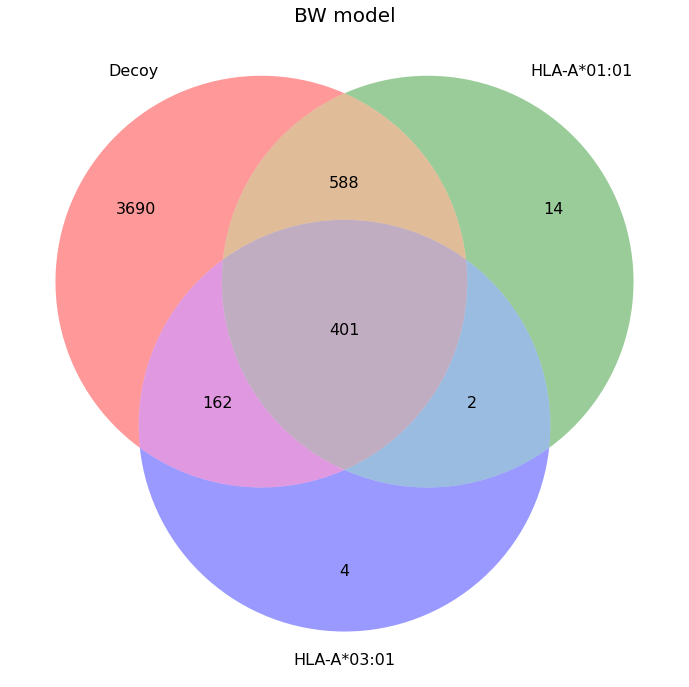

In [43]:

fig, ax = plt.subplots(ncols=1, nrows=1, figsize=[20, 12])

check_intersection2(decoy_bw_paths_df, allele1_bw_paths_df, allele2_bw_paths_df, ax, allele1, allele2)
ax.set_title('BW model',  fontsize=title_font_size)



Text(0.5, 1.0, 'V model')

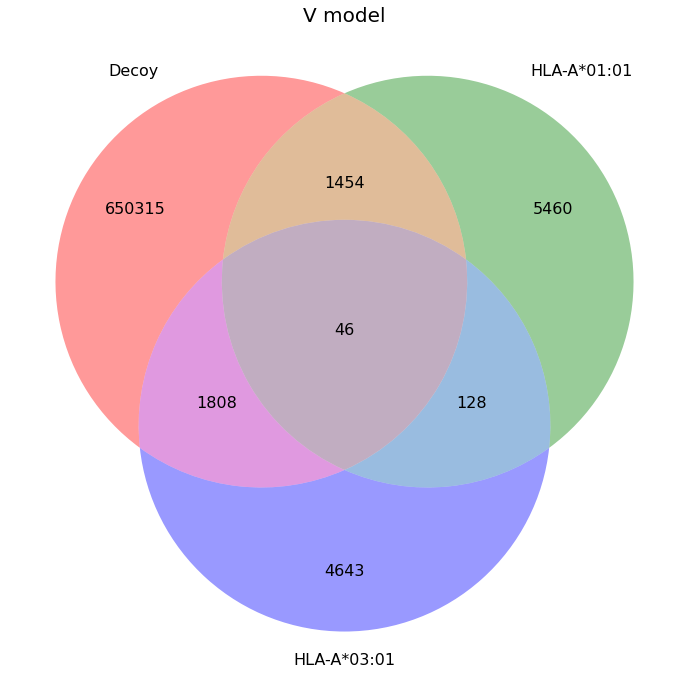

In [44]:
fig, ax = plt.subplots(ncols=1, nrows=1, figsize=[20, 12])

check_intersection2(decoy_v_paths_df, allele1_v_paths_df, allele2_v_paths_df,ax, allele1, allele2)
ax.set_title('V model',  fontsize=title_font_size)


In [66]:
allele2_v_paths_df['path'].iloc[1]

'grouped_model-start>s000>s005>s014>s017>s016>s017>s023>s020>s021>grouped_model-end'

In [106]:
allele1_v_paths_df['exp_prob'] = np.exp(allele1_v_paths_df['prob'])
allele2_v_paths_df['exp_prob'] = np.exp(allele2_v_paths_df['prob'])
decoy_v_paths_df['exp_prob'] = np.exp(decoy_v_paths_df['prob'])

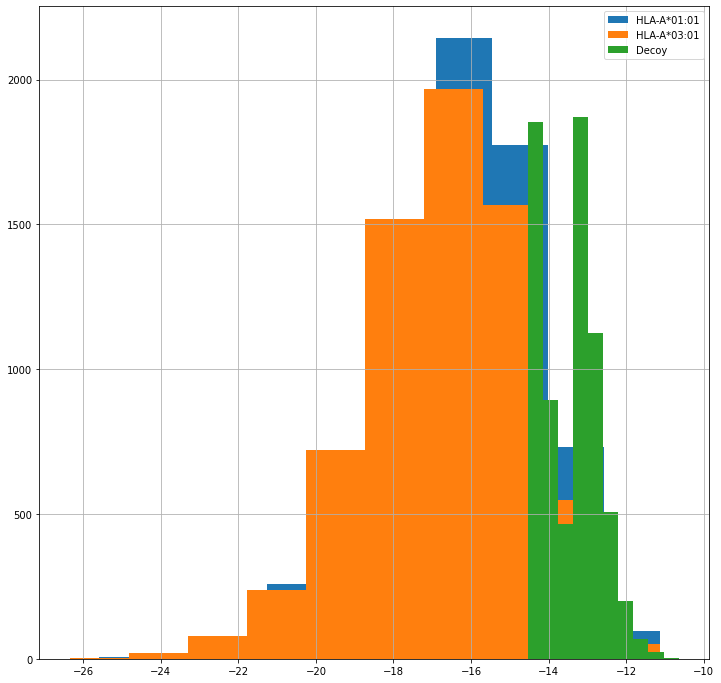

In [107]:
fig, ax = plt.subplots(ncols=1, nrows=1, figsize=[12, 12])
        
allele1_v_paths_df['prob'].hist().plot(ax=ax, label=allele1)
allele2_v_paths_df['prob'].hist().plot(ax=ax, label=allele2)
decoy_v_paths_df['prob'][:7000].hist().plot(ax=ax, label='decoy')
plt.legend([allele1, allele2, 'Decoy'])

<AxesSubplot:>

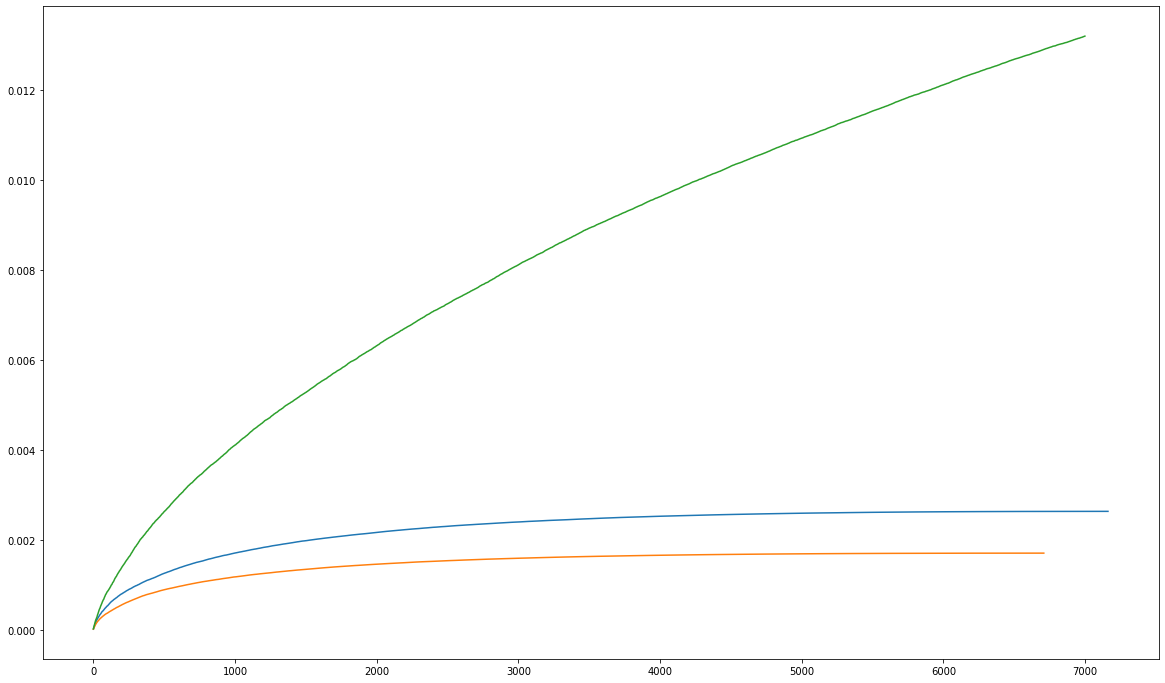

In [108]:
fig, ax = plt.subplots(ncols=1, nrows=1, figsize=[20, 12])
        
allele1_v_paths_df['exp_prob'].cumsum().plot(ax=ax)
allele2_v_paths_df['exp_prob'].cumsum().plot(ax=ax)
decoy_v_paths_df[:7000]['exp_prob'].cumsum().plot(ax=ax)


# Compare binders vs non-binders vs decoy

In [109]:
# Get allele peptides 
allele1_b_peptides = np.concatenate([per_allele_per_kfold_per_length_binders_train[allele1][0][target_length] for target_length in TARGET_LENGTHS])
allele2_b_peptides = np.concatenate([per_allele_per_kfold_per_length_binders_train[allele2][0][target_length] for target_length in TARGET_LENGTHS])
# non-binders peptides
allele1_nb_peptides = np.concatenate([per_allele_per_kfold_per_length_non_binders_train[allele1][0][target_length] for target_length in TARGET_LENGTHS])
allele2_nb_peptides = np.concatenate([per_allele_per_kfold_per_length_non_binders_train[allele2][0][target_length] for target_length in TARGET_LENGTHS])

In [110]:
allele1_b_bw_paths_df = get_all_viterbi_paths_for_model_and_sequences(bw_model, allele1_b_peptides)
allele1_nb_bw_paths_df = get_all_viterbi_paths_for_model_and_sequences(bw_model, allele1_nb_peptides)

allele1_b_v_paths_df = get_all_viterbi_paths_for_model_and_sequences(v_model, allele1_b_peptides)
allele1_nb_v_paths_df = get_all_viterbi_paths_for_model_and_sequences(v_model, allele1_nb_peptides)

allele2_b_bw_paths_df = get_all_viterbi_paths_for_model_and_sequences(bw_model, allele2_b_peptides)
allele2_nb_bw_paths_df = get_all_viterbi_paths_for_model_and_sequences(bw_model, allele2_nb_peptides)

allele2_b_v_paths_df = get_all_viterbi_paths_for_model_and_sequences(v_model, allele2_b_peptides)
allele2_nb_v_paths_df = get_all_viterbi_paths_for_model_and_sequences(v_model, allele2_nb_peptides)

Model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_02_01+HLA_A_03_01-0
Get viterbi paths for each peptide...


100%|██████████████████████████████████████████████████████████████████| 7516/7516 [00:00<00:00, 51072.73it/s]


Select unique paths...
	Unique paths: 596


100%|████████████████████████████████████████████████████████████████████| 596/596 [00:00<00:00, 38140.51it/s]


Model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_02_01+HLA_A_03_01-0
Get viterbi paths for each peptide...


100%|██████████████████████████████████████████████████████████████████| 2875/2875 [00:00<00:00, 41633.29it/s]


... (22 outputs left out)

Model 0_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_02_01+HLA_A_03_01-0
Get viterbi paths for each peptide...


100%|██████████████████████████████████████████████████████████████████| 3524/3524 [00:00<00:00, 41629.75it/s]


Select unique paths...
	Unique paths: 3050


100%|██████████████████████████████████████████████████████████████████| 3050/3050 [00:00<00:00, 65061.37it/s]


In [111]:
data_dict = {
    "V": {
        allele1: {"B":allele1_b_v_paths_df, "NB":allele1_nb_v_paths_df},
        allele2: {"B":allele2_b_v_paths_df, "NB": allele2_nb_v_paths_df},
        "decoy": decoy_v_paths_df
    },
    "BW": {
        allele1: {"B":allele1_b_bw_paths_df, "NB":allele1_nb_bw_paths_df},
        allele2: {"B":allele2_b_bw_paths_df, "NB": allele2_nb_bw_paths_df},
        "decoy": decoy_bw_paths_df
    }
}

In [112]:
len(allele1_nb_peptides)
len(allele2_nb_peptides)

3524

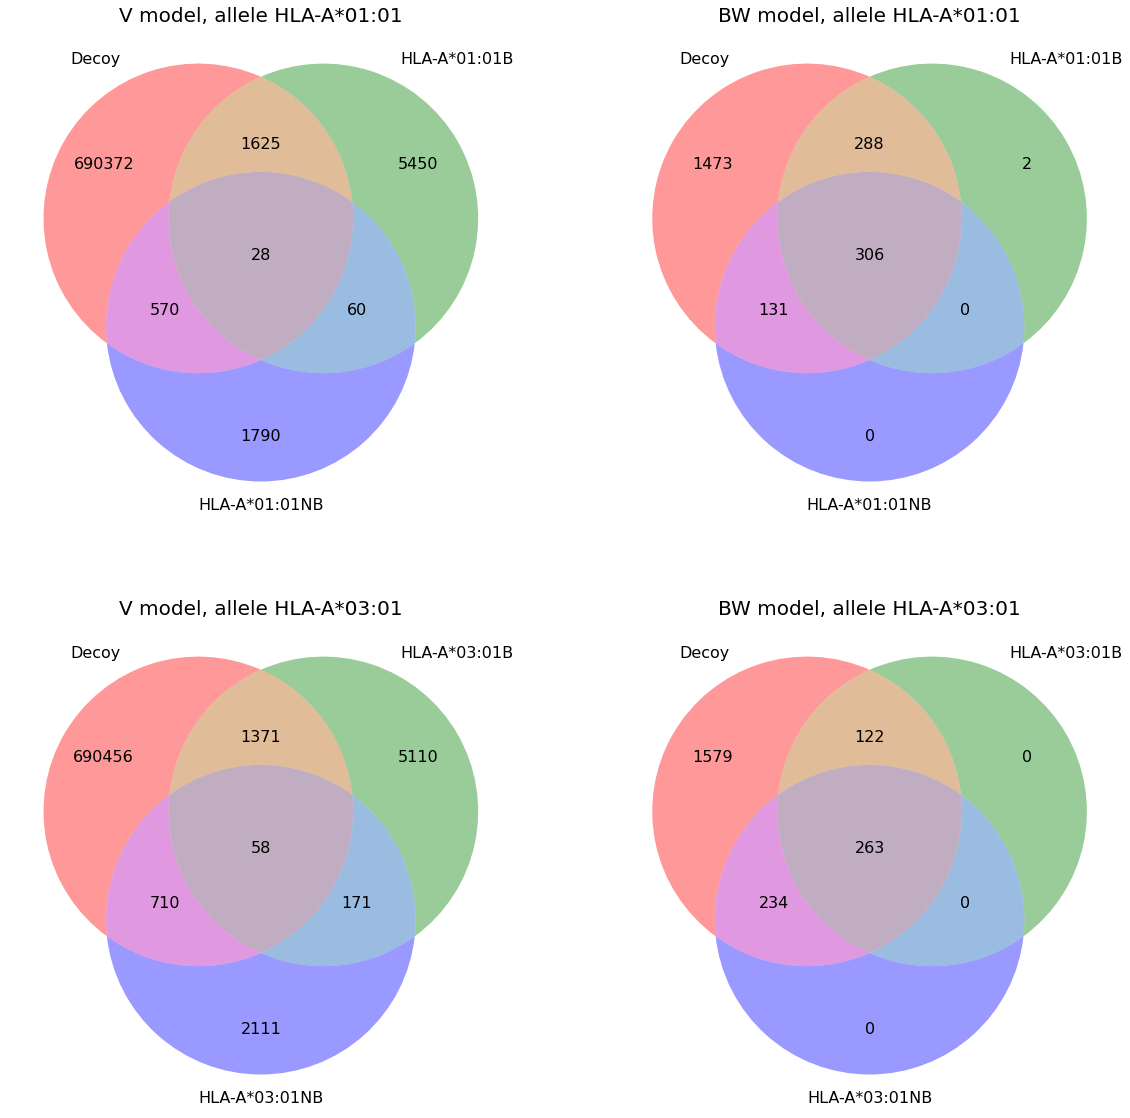

In [113]:
fig, axes = plt.subplots(ncols=2, nrows=2, figsize=[20, 20])

for i, algo in enumerate(["V", "BW"]):
    for j, allele_name in enumerate([allele1, allele2]):
        binder_paths = data_dict[algo][allele_name]["B"]
        non_binder_paths = data_dict[algo][allele_name]["NB"]
        decoy_paths = data_dict[algo]['decoy']
        check_intersection2(decoy_paths, binder_paths, non_binder_paths,axes[j][i], allele_name + "B", allele_name + "NB")
        axes[j][i].set_title(f'{algo} model, allele {allele_name}',  fontsize=title_font_size)


        

Text(0.5, 1.0, 'V model, allele HLA-A*01:01')

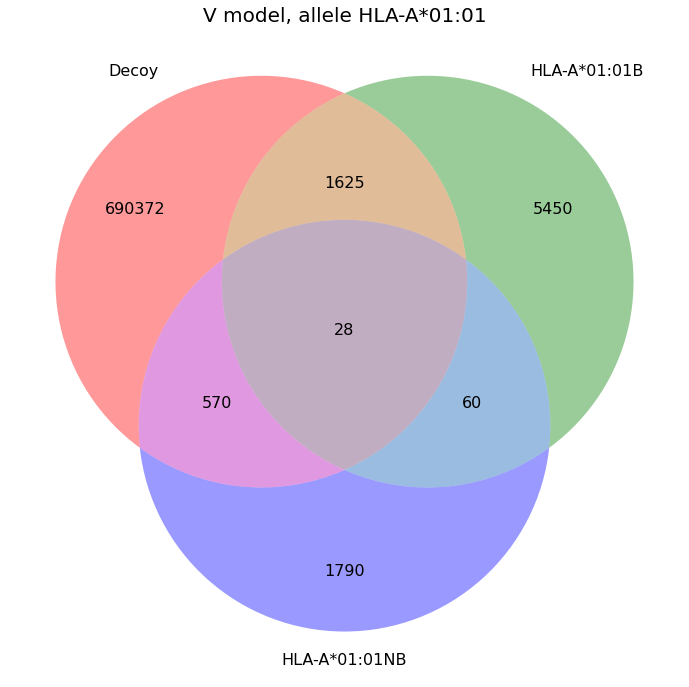

In [114]:
fig, ax = plt.subplots(ncols=1, nrows=1, figsize=[20, 12])

check_intersection2(decoy_v_paths_df, allele1_b_v_paths_df, allele1_nb_v_paths_df,ax, allele1 + "B", allele1 + "NB")
ax.set_title(f'V model, allele {allele1}',  fontsize=title_font_size)


Text(0.5, 1.0, 'BW model, allele HLA-A*01:01')

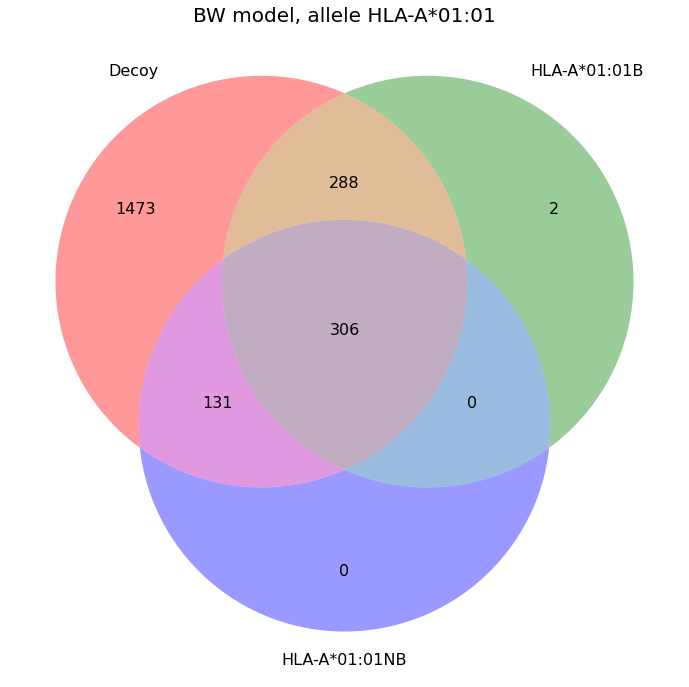

In [115]:
fig, ax = plt.subplots(ncols=1, nrows=1, figsize=[20, 12])

check_intersection2(decoy_bw_paths_df, allele1_b_bw_paths_df, allele1_nb_bw_paths_df,ax, allele1 + "B", allele1 + "NB")
ax.set_title(f'BW model, allele {allele1}',  fontsize=title_font_size)


## Check train paths vs test paths

In [116]:
# Get allele peptides 
allele1_tr_peptides = np.concatenate([per_allele_per_kfold_per_length_binders_train[allele1][0][target_length] for target_length in TARGET_LENGTHS])
allele2_tr_peptides = np.concatenate([per_allele_per_kfold_per_length_binders_train[allele2][0][target_length] for target_length in TARGET_LENGTHS])
# non-binders peptides
allele1_te_peptides = np.concatenate([per_allele_per_kfold_per_length_binders_test[allele1][0][target_length] for target_length in TARGET_LENGTHS])
allele2_te_peptides = np.concatenate([per_allele_per_kfold_per_length_binders_test[allele2][0][target_length] for target_length in TARGET_LENGTHS])

In [117]:
allele1_tr_bw_paths_df = get_all_viterbi_paths_for_model_and_sequences(bw_model, allele1_tr_peptides)
allele1_te_bw_paths_df = get_all_viterbi_paths_for_model_and_sequences(bw_model, allele1_te_peptides)

allele1_tr_v_paths_df = get_all_viterbi_paths_for_model_and_sequences(v_model, allele1_tr_peptides)
allele1_te_v_paths_df = get_all_viterbi_paths_for_model_and_sequences(v_model, allele1_te_peptides)

allele2_tr_bw_paths_df = get_all_viterbi_paths_for_model_and_sequences(bw_model, allele2_tr_peptides)
allele2_te_bw_paths_df = get_all_viterbi_paths_for_model_and_sequences(bw_model, allele2_te_peptides)

allele2_tr_v_paths_df = get_all_viterbi_paths_for_model_and_sequences(v_model, allele2_tr_peptides)
allele2_te_v_paths_df = get_all_viterbi_paths_for_model_and_sequences(v_model, allele2_te_peptides)

Model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_02_01+HLA_A_03_01-0
Get viterbi paths for each peptide...


100%|██████████████████████████████████████████████████████████████████| 7516/7516 [00:00<00:00, 46168.34it/s]


Select unique paths...
	Unique paths: 596


100%|████████████████████████████████████████████████████████████████████| 596/596 [00:00<00:00, 38150.99it/s]


Model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_02_01+HLA_A_03_01-0
Get viterbi paths for each peptide...


100%|██████████████████████████████████████████████████████████████████| 1881/1881 [00:00<00:00, 35209.44it/s]


... (22 outputs left out)

Model 0_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_02_01+HLA_A_03_01-0
Get viterbi paths for each peptide...


100%|██████████████████████████████████████████████████████████████████| 1829/1829 [00:00<00:00, 29261.99it/s]


Select unique paths...
	Unique paths: 1799


100%|██████████████████████████████████████████████████████████████████| 1799/1799 [00:00<00:00, 47600.01it/s]


In [118]:
data_dict = {
    "V": {
        allele1: {"Train":allele1_tr_v_paths_df, "Test":allele1_te_v_paths_df},
        allele2: {"Train":allele2_tr_v_paths_df, "Test": allele2_te_v_paths_df},
        "decoy": decoy_v_paths_df
    },
    "BW": {
        allele1: {"Train":allele1_tr_bw_paths_df, "Test":allele1_te_bw_paths_df},
        allele2: {"Train":allele2_tr_bw_paths_df, "Test": allele2_te_bw_paths_df},
        "decoy": decoy_bw_paths_df
    }
}

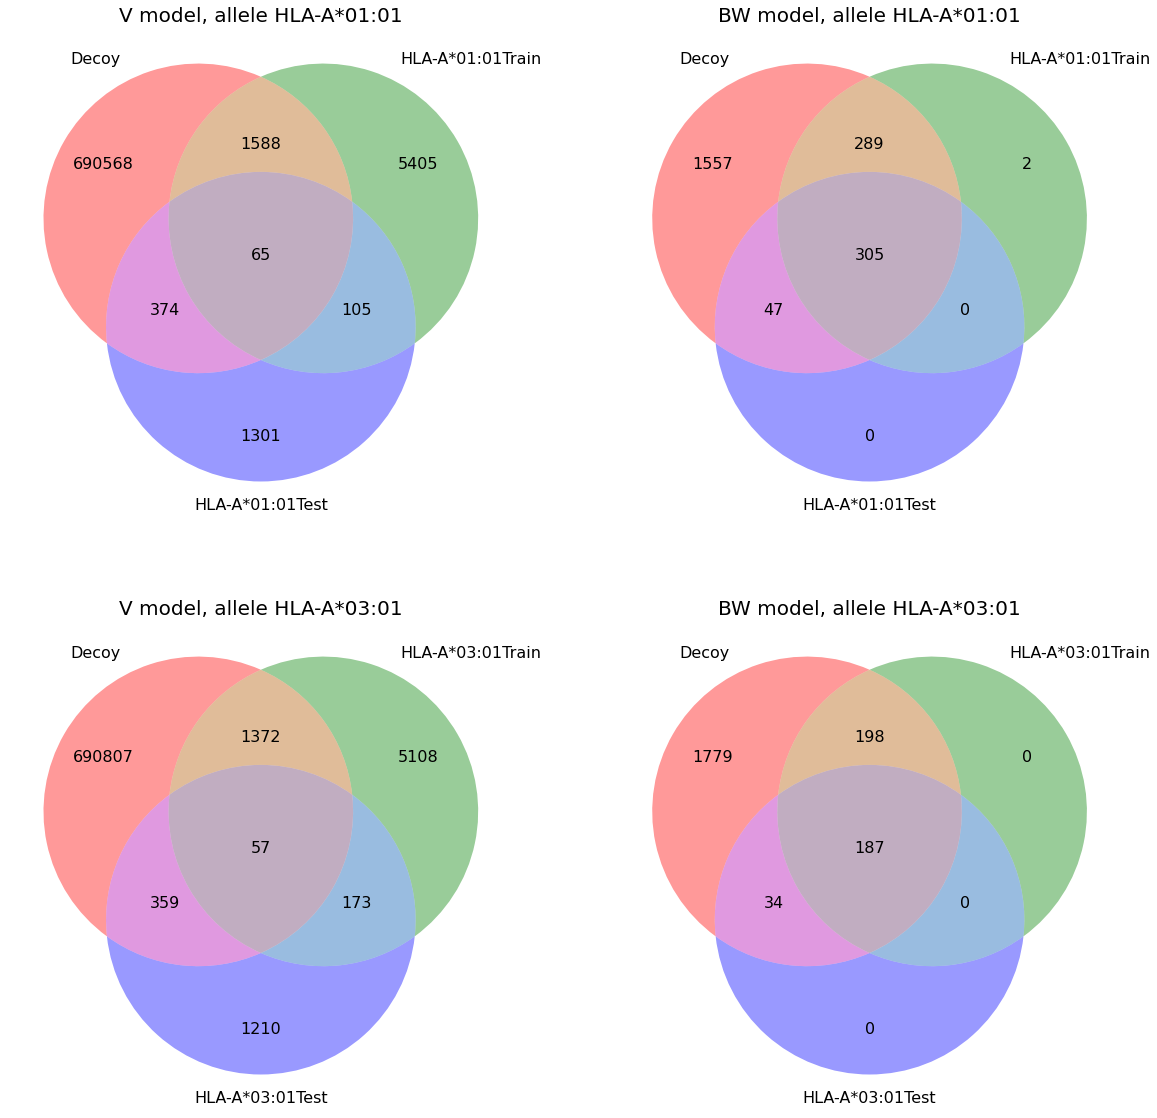

In [119]:
fig, axes = plt.subplots(ncols=2, nrows=2, figsize=[20, 20])

for i, algo in enumerate(["V", "BW"]):
    for j, allele_name in enumerate([allele1, allele2]):
        binder_paths = data_dict[algo][allele_name]["Train"]
        non_binder_paths = data_dict[algo][allele_name]["Test"]
        decoy_paths = data_dict[algo]['decoy']
        check_intersection2(decoy_paths, binder_paths, non_binder_paths,axes[j][i], allele_name + "Train", allele_name + "Test")
        axes[j][i].set_title(f'{algo} model, allele {allele_name}',  fontsize=title_font_size)



In [139]:
allele1_tr_bw_paths_df['peptide_cnts'].value_counts()

1      212
2       83
3       45
4       37
5       23
      ... 
176      1
46       1
111      1
156      1
26       1
Name: peptide_cnts, Length: 75, dtype: int64

In [120]:
allele1_te_v_paths_df['peptide_cnts'].value_counts()

1    1812
2      30
3       3
Name: peptide_cnts, dtype: int64

In [121]:
allele1_tr_v_paths_df['peptide_cnts'].value_counts()

1    6883
2     229
3      35
4      12
5       3
7       1
Name: peptide_cnts, dtype: int64

In [122]:
decoy_v_paths_df['peptide_cnts'].value_counts()

1     618265
2      54581
3      12225
4       3927
5       1746
6        804
7        394
8        223
9        151
10        89
11        58
12        46
14        27
13        15
16        11
15        11
18         6
19         5
20         4
17         3
22         1
26         1
25         1
21         1
Name: peptide_cnts, dtype: int64

In [123]:
allele1_te_v_paths_df

,path,prob,normalized_prob,len,mean_viterbi,peptide_cnts
0,grouped_model-start>s003>s001>s005>s013>s012>s...,-11.178525,-1.016230,9,-23.600115,1
1,grouped_model-start>s003>s001>s005>s013>s012>s...,-12.553098,-1.046091,10,-28.052895,1
2,grouped_model-start>s003>s001>s009>s005>s013>s...,-11.540055,-1.049096,9,-23.685116,1
3,grouped_model-start>s002>s009>s005>s013>s012>s...,-11.568565,-1.051688,9,-25.116326,1
4,grouped_model-start>s003>s001>s005>s013>s012>s...,-11.745002,-1.067727,9,-24.321089,1
...,...,...,...,...,...,...
1840,grouped_model-start>s003>s007>s010>s012>s017>s...,-23.359118,-1.946593,10,-34.141610,1
1841,grouped_model-start>s003>s009>s014>s011>s018>s...,-21.597404,-1.963400,9,-29.682352,1
1842,grouped_model-start>s002>s009>s012>s011>s010>s...,-24.047291,-2.003941,10,-33.849555,1
1843,grouped_model-start>s003>s008>s013>s017>s015>s...,-23.211429,-2.110130,9,-34.705633,1


## Convert model (delete edges less than precision) and then again calculate intersections

In [124]:
from hmm_logic_methods import copy_model_with_pseudocounts
precision = 3
#make copy of model but with precision here

new_v_model = copy_model_with_pseudocounts(v_model, precision = 1)
new_bw_model = copy_model_with_pseudocounts(bw_model, precision = 3)

 N is  25
sum from start 1.1
 N is  25
sum from start 1.0


In [125]:
decoy_v_paths_df = get_all_viterbi_paths_for_model_and_sequences(new_v_model, peptides_for_analysis)
decoy_bw_paths_df = get_all_viterbi_paths_for_model_and_sequences(new_bw_model, peptides_for_analysis)


Model 0_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_02_01+HLA_A_03_01-0
Get viterbi paths for each peptide...


100%|██████████████████████████████████████████████████████████████| 802687/802687 [00:25<00:00, 31755.50it/s]


Select unique paths...
	Unique paths: 616882


100%|█████████████████████████████████████████████████████████████| 616882/616882 [00:05<00:00, 113907.34it/s]


Model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_02_01+HLA_A_03_01-0
Get viterbi paths for each peptide...


100%|██████████████████████████████████████████████████████████████| 802687/802687 [00:23<00:00, 34305.76it/s]


Select unique paths...
	Unique paths: 2198


100%|██████████████████████████████████████████████████████████████████| 2198/2198 [00:00<00:00, 58178.49it/s]


In [126]:
# Get allele peptides 
allele1_peptides = np.concatenate([per_allele_per_kfold_per_length_binders_train[allele1][0][target_length] for target_length in TARGET_LENGTHS])
allele2_peptides = np.concatenate([per_allele_per_kfold_per_length_binders_train[allele2][0][target_length] for target_length in TARGET_LENGTHS])

In [127]:
allele1_bw_paths_df = get_all_viterbi_paths_for_model_and_sequences(new_bw_model, allele1_peptides)
allele1_v_paths_df = get_all_viterbi_paths_for_model_and_sequences(new_v_model, allele1_peptides)
allele2_bw_paths_df = get_all_viterbi_paths_for_model_and_sequences(new_bw_model, allele2_peptides)
allele2_v_paths_df = get_all_viterbi_paths_for_model_and_sequences(new_v_model, allele2_peptides)

Model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_02_01+HLA_A_03_01-0
Get viterbi paths for each peptide...


100%|██████████████████████████████████████████████████████████████████| 7516/7516 [00:00<00:00, 27880.66it/s]


Select unique paths...
	Unique paths: 596


100%|███████████████████████████████████████████████████████████████████████████████| 596/596 [00:00<?, ?it/s]


Model 0_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_02_01+HLA_A_03_01-0
Get viterbi paths for each peptide...


100%|██████████████████████████████████████████████████████████████████| 7516/7516 [00:00<00:00, 24984.32it/s]


... (6 outputs left out)

Model 0_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_02_01+HLA_A_03_01-0
Get viterbi paths for each peptide...


100%|██████████████████████████████████████████████████████████████████| 7316/7316 [00:00<00:00, 24313.48it/s]


Select unique paths...
	Unique paths: 6676


100%|██████████████████████████████████████████████████████████████████| 6676/6676 [00:00<00:00, 78875.66it/s]


In [128]:
print("BW")
check_intersection(decoy_bw_paths_df, allele1_bw_paths_df, allele1)
check_intersection(decoy_bw_paths_df, allele2_bw_paths_df, allele2)
print("V")
check_intersection(decoy_v_paths_df, allele1_v_paths_df, allele1)
check_intersection(decoy_v_paths_df, allele2_v_paths_df, allele2)


BW
for allele HLA-A*01:01
 len of decoy = 2198, len of allele 596, intersection 594
for allele HLA-A*03:01
 len of decoy = 2198, len of allele 385, intersection 385
V
for allele HLA-A*01:01
 len of decoy = 616882, len of allele 7120, intersection 2210
for allele HLA-A*03:01
 len of decoy = 616882, len of allele 6676, intersection 2090


Text(0.5, 1.0, 'BW model')

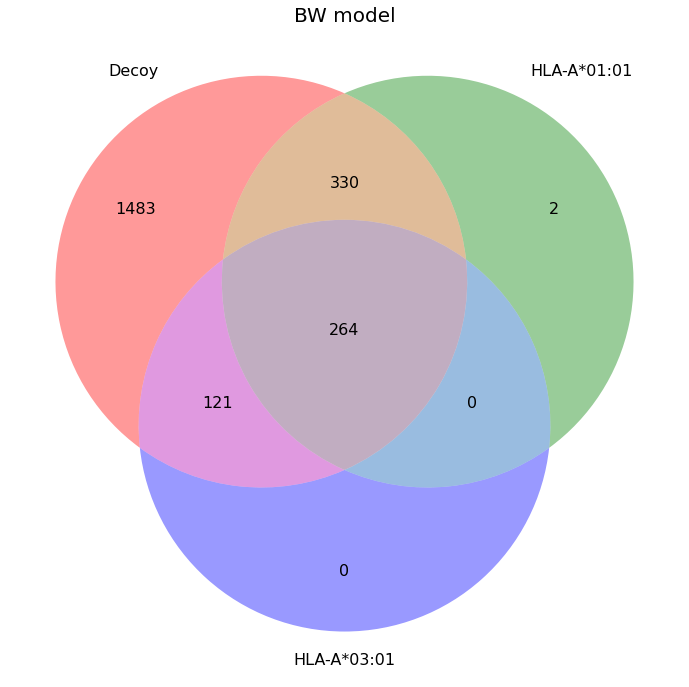

In [129]:
fig, ax = plt.subplots(ncols=1, nrows=1, figsize=[20, 12])

check_intersection2(decoy_bw_paths_df, allele1_bw_paths_df, allele2_bw_paths_df, ax, allele1, allele2)
ax.set_title('BW model',  fontsize=title_font_size)



Text(0.5, 1.0, 'V model')

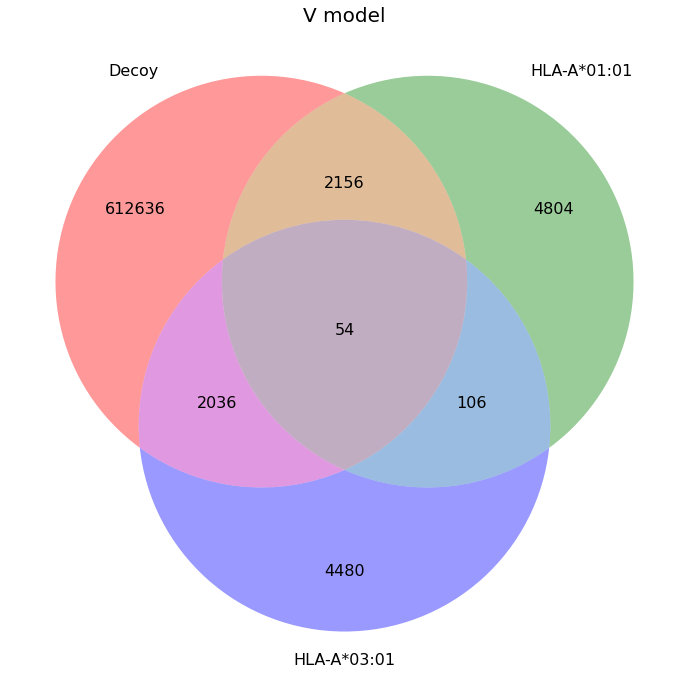

In [130]:
fig, ax = plt.subplots(ncols=1, nrows=1, figsize=[20, 12])

check_intersection2(decoy_v_paths_df, allele1_v_paths_df, allele2_v_paths_df, ax, allele1, allele2)
ax.set_title('V model',  fontsize=title_font_size)


In [134]:
allele2_v_paths_df['peptide_cnts'].value_counts()

1    6150
2     443
3      60
4      16
5       6
6       1
Name: peptide_cnts, dtype: int64

In [131]:
pd.DataFrame(v_model.dense_transition_matrix())

,0,1,2,3,4,5,6,7,8,9,...,17,18,19,20,21,22,23,24,25,26
0,0.000000,0.366462,1.523295e-02,0.005373,0.031278,8.188129e-28,3.885834e-03,0.134337,0.307130,0.136300,...,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000
1,0.023824,0.000000,3.556450e-08,0.038835,0.030994,2.898689e-01,3.993239e-02,0.077193,0.267821,0.231532,...,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000
2,0.029417,0.300277,0.000000e+00,0.016461,0.061958,2.198560e-02,3.542860e-04,0.084267,0.271434,0.213845,...,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000
3,0.018507,0.387404,3.007183e-02,0.000000,0.043546,8.171741e-04,4.370470e-03,0.065863,0.240406,0.209015,...,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000
4,0.016297,0.297416,3.066964e-02,0.010349,0.000000,1.734471e-24,3.100657e-25,0.072634,0.404353,0.168282,...,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000
5,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000e+00,7.026319e-02,0.127969,0.007254,0.110423,...,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000
6,0.000000,0.000000,0.000000e+00,0.000000,0.000000,1.269150e-01,0.000000e+00,0.039160,0.003285,0.049607,...,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000
7,0.000000,0.000000,0.000000e+00,0.000000,0.000000,2.385307e-01,6.080154e-02,0.000000,0.007930,0.089212,...,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000
8,0.000000,0.000000,0.000000e+00,0.000000,0.000000,3.455524e-01,7.251067e-02,0.102338,0.000000,0.115298,...,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000
9,0.000000,0.000000,0.000000e+00,0.000000,0.000000,3.887128e-01,6.186046e-02,0.052325,0.089113,0.000000,...,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0,0.000000


In [132]:
pd.DataFrame(new_v_model.dense_transition_matrix())

,0,1,2,3,4,5,6,7,8,9,...,17,18,19,20,21,22,23,24,25,26
0,0.000000,0.444444,0.000000,0.000000,0.000000,0.000000,0.000000,0.111111,0.333333,0.111111,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000
1,0.000000,0.000000,0.000000,0.000000,0.000000,0.333333,0.000000,0.111111,0.333333,0.222222,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000
2,0.000000,0.300000,0.000000,0.000000,0.100000,0.000000,0.000000,0.100000,0.300000,0.200000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000
3,0.000000,0.444444,0.000000,0.000000,0.000000,0.000000,0.000000,0.111111,0.222222,0.222222,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000
4,0.000000,0.300000,0.000000,0.000000,0.000000,0.000000,0.000000,0.100000,0.400000,0.200000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000
5,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.100000,0.100000,0.000000,0.100000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000
6,0.000000,0.000000,0.000000,0.000000,0.000000,0.111111,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000
7,0.000000,0.000000,0.000000,0.000000,0.000000,0.200000,0.100000,0.000000,0.000000,0.100000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000
8,0.000000,0.000000,0.000000,0.000000,0.000000,0.300000,0.100000,0.100000,0.000000,0.100000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000
9,0.000000,0.000000,0.000000,0.000000,0.000000,0.363636,0.090909,0.090909,0.090909,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000


## Maybe need another sorting

In [35]:
decoy_v_paths_df

,path,prob,normalized_prob,len,mean_viterbi,peptide_cnts,exp_prob
0,grouped_model-start>s000>s005>s014>s017>s016>s...,-10.712701,-0.973882,9,-28.347163,1,2.226040e-05
1,grouped_model-start>s000>s005>s013>s017>s016>s...,-10.717674,-0.974334,9,-28.607292,9,2.214999e-05
2,grouped_model-start>s000>s008>s014>s017>s016>s...,-10.821247,-0.983750,9,-30.335843,11,1.997064e-05
3,grouped_model-start>s000>s007>s014>s017>s016>s...,-10.882990,-0.989363,9,-30.252498,5,1.877489e-05
4,grouped_model-start>s000>s005>s013>s010>s017>s...,-10.892385,-0.990217,9,-28.341529,2,1.859934e-05
...,...,...,...,...,...,...,...
653618,grouped_model-start>s004>s003>s006>s012>s014>s...,-29.775507,-2.706864,9,-41.994170,1,1.171282e-13
653619,grouped_model-start>s002>s003>s002>s004>s005>s...,-29.828904,-2.711719,9,-40.865855,1,1.110380e-13
653620,grouped_model-start>s001>s003>s002>s006>s013>s...,-29.980797,-2.725527,9,-40.145774,1,9.539050e-14
653621,grouped_model-start>s002>s003>s000>s006>s010>s...,-31.135519,-2.830502,9,-44.688708,1,3.006185e-14


In [42]:
decoy_v_paths_df.sort_values(by='peptide_cnts', ascending = False)

,path,prob,normalized_prob,len,mean_viterbi,peptide_cnts,exp_prob
3089,grouped_model-start>s000>s008>s014>s017>s023>s...,-12.773361,-1.161215,9,-30.699776,59,2.835304e-06
3489,grouped_model-start>s000>s007>s014>s017>s023>s...,-12.835104,-1.166828,9,-31.821809,47,2.665540e-06
6681,grouped_model-start>s000>s007>s013>s017>s023>s...,-13.216147,-1.201468,9,-32.339629,41,1.820959e-06
5658,grouped_model-start>s000>s007>s014>s017>s023>s...,-13.113078,-1.192098,9,-31.600861,34,2.018657e-06
272,grouped_model-start>s000>s008>s014>s017>s023>s...,-11.823864,-1.074897,9,-29.998056,33,7.327590e-06
...,...,...,...,...,...,...,...
253678,grouped_model-start>s000>s002>s000>s007>s011>s...,-18.738057,-1.561505,10,-36.917020,1,7.280567e-09
253677,grouped_model-start>s000>s007>s013>s017>s019>s...,-17.176540,-1.561504,9,-36.622258,1,3.469950e-08
253676,grouped_model-start>s000>s006>s014>s017>s016>s...,-18.738044,-1.561504,10,-33.376468,1,7.280664e-09
253675,grouped_model-start>s004>s000>s006>s012>s014>s...,-17.176540,-1.561504,9,-29.978159,1,3.469953e-08


In [49]:
(decoy_v_paths_df['peptide_cnts'] > 1).value_counts()

False    566081
True      87542
Name: peptide_cnts, dtype: int64

In [50]:
(allele1_v_paths_df['peptide_cnts'] > 1).value_counts()

False    6745
True      343
Name: peptide_cnts, dtype: int64

In [51]:
(allele2_v_paths_df['peptide_cnts'] > 1).value_counts()

False    6069
True      556
Name: peptide_cnts, dtype: int64

<AxesSubplot:>

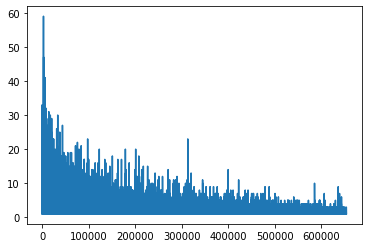

In [ ]:
decoy_v_paths_df['peptide_cnts'].plot()

In [70]:
filtered_decoy_paths = decoy_v_paths_df[(decoy_v_paths_df['peptide_cnts'] > 1)]
filtered_allele1_paths = allele1_v_paths_df[(allele1_v_paths_df['peptide_cnts'] > 1)]
filtered_allele2_paths = allele2_v_paths_df[(allele2_v_paths_df['peptide_cnts'] > 1)]

Text(0.5, 1.0, 'V model')

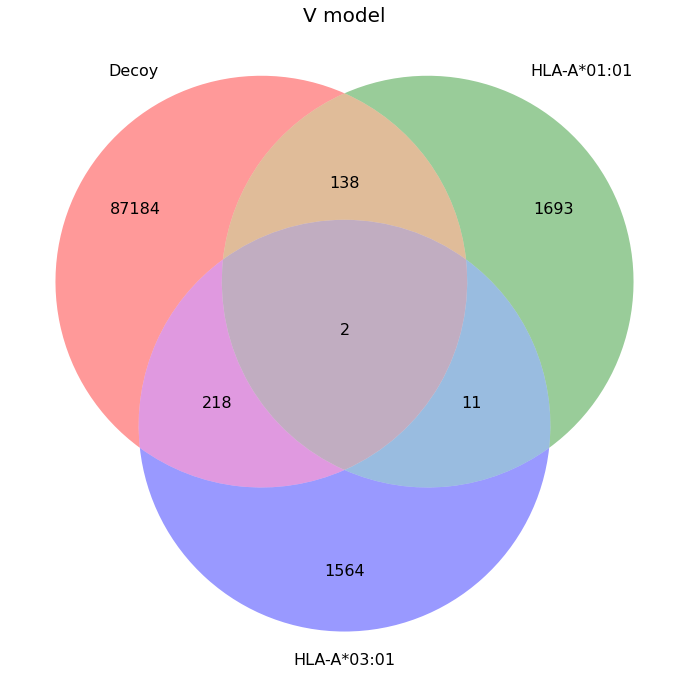

In [71]:
fig, ax = plt.subplots(ncols=1, nrows=1, figsize=[20, 12])

check_intersection2(filtered_decoy_paths, allele1_v_paths_df, allele2_v_paths_df,ax, allele1, allele2)
ax.set_title('V model',  fontsize=title_font_size)


In [59]:
sorted_decoy_v_paths_df = decoy_v_paths_df.sort_values(by='mean_viterbi', ascending = False)
sorted_decoy_v_paths_df

,path,prob,normalized_prob,len,mean_viterbi,peptide_cnts,exp_prob
101250,grouped_model-start>s003>s007>s008>s011>s016>s...,-15.648113,-1.422556,9,-20.426795,1,1.599967e-07
18674,grouped_model-start>s003>s005>s011>s017>s016>s...,-13.941633,-1.267421,9,-21.247421,1,8.815069e-07
976,grouped_model-start>s000>s005>s008>s014>s017>s...,-12.246533,-1.113321,9,-21.517653,1,4.801738e-06
3147,grouped_model-start>s000>s008>s011>s017>s016>s...,-12.782616,-1.162056,9,-21.530819,1,2.809187e-06
3627,grouped_model-start>s000>s005>s009>s011>s014>s...,-12.856399,-1.168764,9,-21.665050,1,2.609378e-06
...,...,...,...,...,...,...,...
474418,grouped_model-start>s002>s006>s013>s019>s018>s...,-20.985399,-1.748783,10,-57.470355,1,7.694082e-10
449672,grouped_model-start>s003>s008>s006>s013>s019>s...,-20.693128,-1.724427,10,-58.719402,1,1.030597e-09
455342,grouped_model-start>s003>s007>s006>s013>s019>s...,-20.758252,-1.729854,10,-59.276576,2,9.656185e-10
556469,grouped_model-start>s000>s002>s006>s013>s019>s...,-22.195689,-1.849641,10,-59.457991,1,2.293690e-10


Text(0.5, 1.0, 'V model')

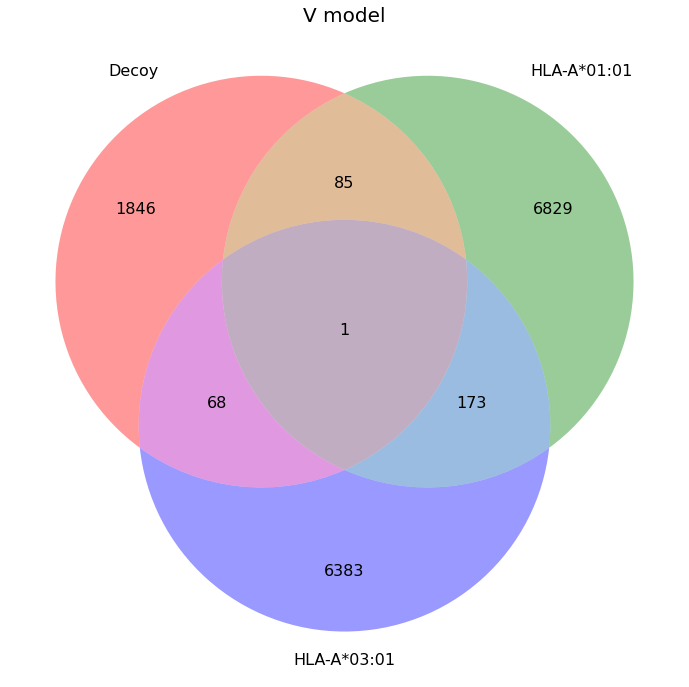

In [60]:
fig, ax = plt.subplots(ncols=1, nrows=1, figsize=[20, 12])

check_intersection2(sorted_decoy_v_paths_df[:2000], allele1_v_paths_df, allele2_v_paths_df,ax, allele1, allele2)
ax.set_title('V model',  fontsize=title_font_size)

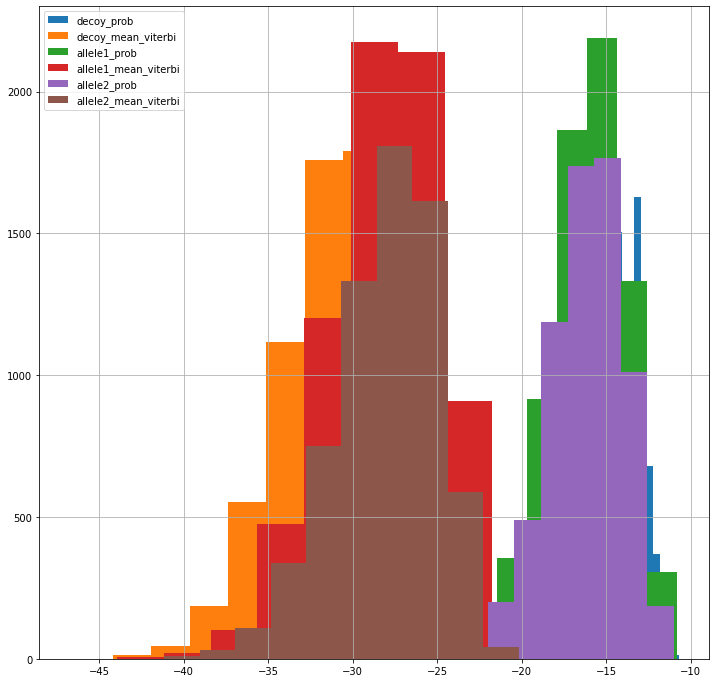

In [39]:
fig, ax = plt.subplots(ncols=1, nrows=1, figsize=[12, 12])
        
decoy_v_paths_df['prob'][:7000].hist().plot(ax=ax, )
decoy_v_paths_df['mean_viterbi'][:7000].hist().plot(ax=ax, )
allele1_v_paths_df['prob'].hist().plot(ax=ax, )
allele1_v_paths_df['mean_viterbi'].hist().plot(ax=ax, )

allele2_v_paths_df['prob'].hist().plot(ax=ax, )
allele2_v_paths_df['mean_viterbi'].hist().plot(ax=ax, )

plt.legend(['decoy_prob', 'decoy_mean_viterbi', 'allele1_prob', 'allele1_mean_viterbi', 'allele2_prob', 'allele2_mean_viterbi'])

In [28]:
paths_df['exp_prob'] = np.exp(paths_df['prob'])


In [29]:
paths_df['exp_prob'].cumsum().iloc[10]

0.06277501821407636

In [30]:
paths_df['exp_prob'].cumsum().iloc[1000]

0.6892319261925545

<AxesSubplot:>

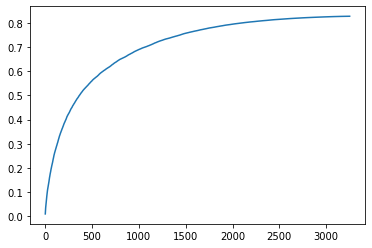

In [31]:
paths_df['exp_prob'].cumsum().plot()

<AxesSubplot:>

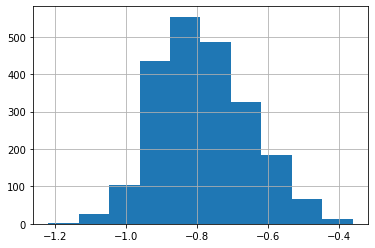

In [35]:
paths_df['normalized_prob'].hist()

<AxesSubplot:>

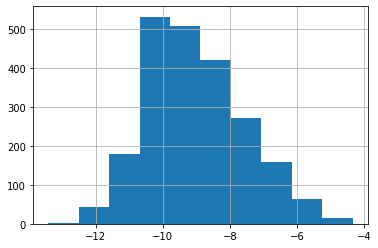

In [37]:
paths_df['prob'].hist()

In [28]:
paths_df.head(20)

,path,prob,normalized_prob,len,exp_prob
0,grouped_model-start>s001>s002>s005>s010>s012>s...,-4.348953,-0.362413,10,0.012920
1,grouped_model-start>s001>s002>s005>s010>s013>s...,-4.796836,-0.399736,10,0.008256
2,grouped_model-start>s001>s002>s005>s010>s012>s...,-4.798295,-0.399858,10,0.008244
3,grouped_model-start>s001>s002>s005>s010>s011>s...,-4.443446,-0.403950,9,0.011755
4,grouped_model-start>s001>s002>s005>s010>s014>s...,-4.628137,-0.420740,9,0.009773
5,grouped_model-start>s004>s009>s006>s010>s012>s...,-5.095926,-0.424660,10,0.006122
6,grouped_model-start>s001>s002>s005>s013>s011>s...,-4.740401,-0.430946,9,0.008735
7,grouped_model-start>s001>s002>s005>s010>s012>s...,-5.180728,-0.431727,10,0.005624
8,grouped_model-start>s001>s002>s005>s010>s012>s...,-5.207980,-0.433998,10,0.005473
9,grouped_model-start>s001>s002>s005>s010>s013>s...,-5.242446,-0.436870,10,0.005287


<AxesSubplot:>

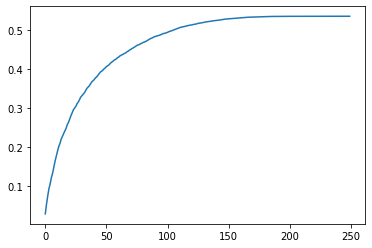

In [36]:
df_bw_paths['exp_prob'].cumsum().plot()

<AxesSubplot:ylabel='exp_prob'>

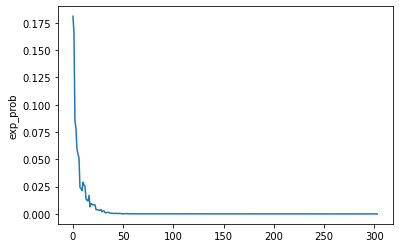

In [37]:
import seaborn as sns
sns.lineplot(data=df_bwv_paths, x=df_bwv_paths.index.values, y='exp_prob')

<AxesSubplot:ylabel='exp_prob'>

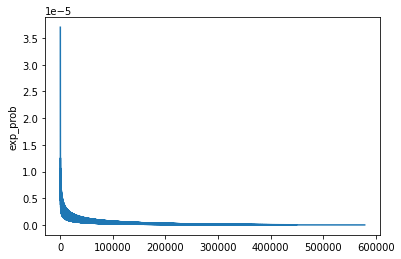

In [38]:
sns.lineplot(data=df_v_paths, x=df_v_paths.index.values, y='exp_prob')

<AxesSubplot:ylabel='exp_prob'>

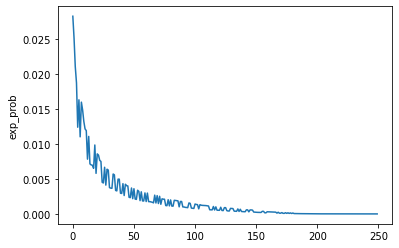

In [39]:
sns.lineplot(data=df_bw_paths, x=df_bw_paths.index.values, y='exp_prob')

In [124]:
#paths probs 3 per position
df_bw_paths.describe()

,prob,exp_prob
count,19683.000000,1.968300e+04
mean,-10.857784,5.080526e-05
std,1.630386,6.636808e-05
min,-15.265151,2.346548e-07
25%,-12.137985,5.352296e-06
50%,-10.528127,2.677272e-05
75%,-9.574887,6.945114e-05
max,-7.397044,6.130621e-04
